In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2,
    preprocess_input,
    decode_predictions,
)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: []


In [9]:
model = MobileNetV2(
    weights="imagenet",
    include_top=True,
)

print("Model loaded successfully")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Parameters:", f"{model.count_params():,}")

Model loaded successfully
Input shape: (None, 224, 224, 3)
Output shape: (None, 1000)
Parameters: 3,538,984


In [7]:
image_path = r"C:\Deep learning CampusX\Data\image.png"

print("Image path:", image_path)

Image path: C:\Deep learning CampusX\Data\image.png


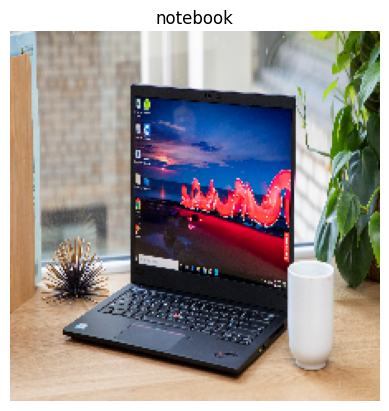

Top 5 predictions:

1. notebook: 57.44%
2. laptop: 35.99%
3. monitor: 1.32%
4. desktop computer: 1.00%
5. space bar: 0.44%


In [10]:
image = keras.utils.load_img(
    image_path,
    target_size=(224, 224),
    color_mode="rgb",
)

image_array = keras.utils.img_to_array(image)
image_batch = np.expand_dims(image_array, axis=0)

processed_image = preprocess_input(image_batch.copy())#pre process the image
predictions = model.predict(processed_image, verbose=0)
top_predictions = decode_predictions(
    predictions,
    top=5,
)[0]

plt.imshow(image)
plt.axis("off")
plt.title(top_predictions[0][1].replace("_", " "))
plt.show()

print("Top 5 predictions:\n")

for rank, (_, class_name, probability) in enumerate(
    top_predictions,
    start=1,
):
    readable_name = class_name.replace("_", " ")
    print(f"{rank}. {readable_name}: {probability:.2%}")

In [ ]:
import time
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("Detected GPUs:", gpus)

assert gpus, "No GPU detected. Check that the WSL GPU kernel is selected."

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

with tf.device("/GPU:0"):
    x = tf.random.normal((2048, 2048))
    y = tf.random.normal((2048, 2048))

    start = time.perf_counter()
    result = tf.matmul(x, y)
    checksum = float(tf.reduce_sum(result).numpy())
    elapsed = time.perf_counter() - start

print("\nGPU check passed!")
print("Calculation device:", result.device)
print("Result shape:", result.shape)
print("Checksum:", checksum)
print(f"Execution time: {elapsed:.3f} seconds")

I0000 00:00:1793044804.061378   13830 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.21.0
Detected GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


I0000 00:00:1793044816.828260   13830 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1767 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6



GPU check passed!
Calculation device: /job:localhost/replica:0/task:0/device:GPU:0
Result shape: (2048, 2048)
Checksum: -25941.779296875
Execution time: 1.263 seconds
